In [9]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

notebook_file = globals().get("__vsc_ipynb_file__")
NOTEBOOK_DIR = Path(notebook_file).resolve().parent if notebook_file else Path.cwd()
sys.path.insert(0, str(NOTEBOOK_DIR))

import evaluation

DATE = "AsOfDate"



prices = pl.read_csv(NOTEBOOK_DIR / "example_prices.csv", try_parse_dates=True).rename({"dates": DATE})
instruments = [c for c in prices.columns if c != DATE]
ret = prices.select(DATE, pl.col(instruments).diff())

In [ ]:
training_data = prices[:4000]
testing_data = prices[4000:5000]
validation_data = prices[5000:]
print(f"Training data shape: {training_data.shape}")
print(f"Testing data shape: {testing_data.shape}")
print(f"Validation data shape: {validation_data.shape}")

Training data shape: (3000, 6)
Testing data shape: (1500, 6)
Validation data shape: (1456, 6)


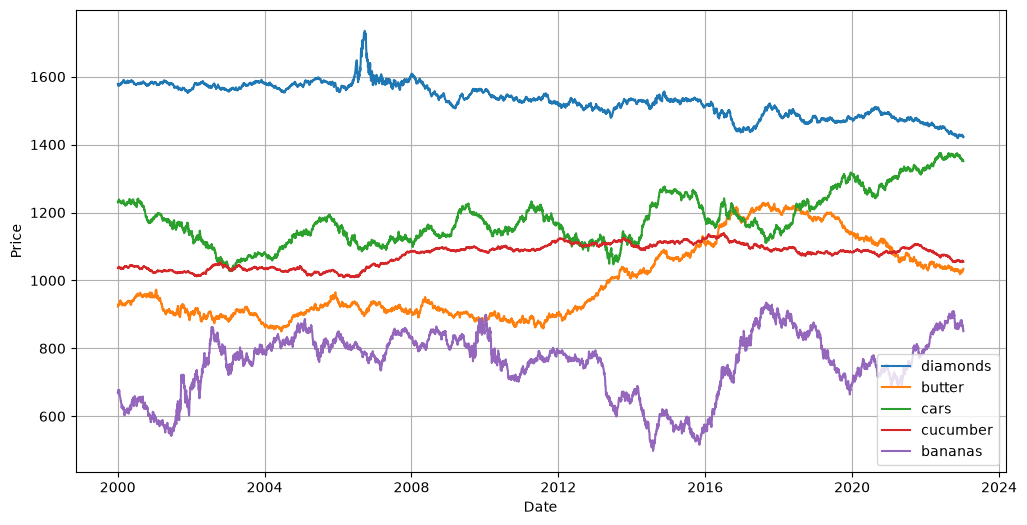

In [18]:
plt.figure(figsize=(12, 6))
for instrument in instruments:
    
    plt.plot(prices[DATE], prices[instrument], label=instrument)
    plt.xlabel("Date")
    plt.ylabel("Price")
plt.legend()
plt.grid()
plt.show()

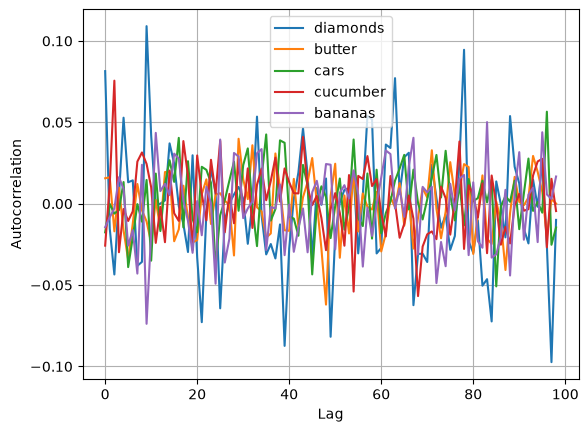

In [45]:
changes = training_data[1:]-training_data[:-1]


import numpy as np

def Autocorr(x, max_lag=None):
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    n = len(x)

    # Zero-padding avoids circular autocorrelation
    n_fft = 1 << (2 * n - 1).bit_length()
    spectrum = np.fft.rfft(x, n=n_fft)
    acov = np.fft.irfft(spectrum * np.conj(spectrum), n=n_fft)[:n]

    # Unbiased normalization, then normalize so lag 0 equals 1
    acov /= np.arange(n, 0, -1)
    acorr = acov / acov[0]

    return acorr if max_lag is None else acorr[:max_lag]
plt.Figure(figsize=(12, 6))
for instrument in instruments:
    corrs = Autocorr(changes[instrument], max_lag=100)
    plt.plot(corrs[1:], label=instrument)

plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.legend()
plt.grid()
plt.show()

In [43]:
A = [[i for i in range(0, 50*j) if i % 2 == 0] for j in range(1, 11)]
print(A)


[[0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48], [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90, 92, 94, 96, 98], [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90, 92, 94, 96, 98, 100, 102, 104, 106, 108, 110, 112, 114, 116, 118, 120, 122, 124, 126, 128, 130, 132, 134, 136, 138, 140, 142, 144, 146, 148], [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56, 58, 60, 62, 64, 66, 68, 70, 72, 74, 76, 78, 80, 82, 84, 86, 88, 90, 92, 94, 96, 98, 100, 102, 104, 106, 108, 110, 112, 114, 116, 118, 120, 122, 124, 126, 128, 130, 132, 134, 136, 138, 140, 142, 144, 146, 148, 150, 152, 154, 156, 158, 160, 162, 164, 166, 168, 170, 172, 17